# E7 — DDR

**PARTIAL / EARLY STOPPED AT EPOCH 10.** E7 tests whether the full 384 px field and two 224 px detail views change diabetic-retinopathy grading. The hypothesis is that they improve validation macro-F1. The run stopped during epoch 11. The best completed checkpoint is epoch 2, selected on frozen validation.

[Notebook index](../README.md) · [Experiment audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md)

## Protocol and reproducibility

[Runner](../../novelty_integrated/e7/runner.py) · [Protocol and environment](../../novelty_integrated/e7/README.md) · [geometry.py](../../novelty_integrated/e7/geometry.py) · [model.py](../../novelty_integrated/e7/model.py) · [input_pipeline.py](../../novelty_integrated/e7/input_pipeline.py) · [config.py](../../novelty_integrated/e7/config.py)

Frozen seed 42 manifest, SHA group isolation, grade order 0–4. Validation uses deterministic transforms and original support. The notebook creates no split.

## Model, inputs and environment

Official Hugging Face ConvNeXt-Tiny V1, pooled width 768. A categorical head emits five logits and an ordered-threshold ordinal head contributes auxiliary supervision. One shared backbone serves the full 384×384 view and two 224×224 patches. A 1,537-parameter gate fuses the pooled global and mean local embeddings. The external checkpoint has no verified count in this checkout.

EXIF-corrected original RGB is letterboxed to 384 px. Two crops use 55% of the estimated field width and height, are letterboxed to 224 px, and use official normalization with resize disabled. B1 train-only augmentation is keyed by seed, epoch and image ID. It applies horizontal flip (p=0.50), field-of-view guarded rotation (p=0.50, ±7°), brightness (p=0.30, factor 0.90–1.10), and contrast (p=0.30, factor 0.90–1.10), in that order. Decoded train RGB can reuse compatible E6 cache read-only, and validation uses an isolated E7 cache.

The evidence view requires Python, Jupyter and IPython. Optional source workflows rely on the run-specific PyTorch, Transformers, Pillow and NumPy environment, a verified local snapshot, and external datasets/manifests. The CLI and protocol links describe hardware, caching and environment details.

### Read committed evidence

The setup uses the dataset-specific result and performs no training or inference.

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import sys

from IPython.display import JSON, display

configured_root = os.environ.get("DR_RESEARCH_ROOT")
start = Path(configured_root).expanduser().resolve() if configured_root else Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "notebooks/experiment_workflow.py").is_file() and (p / "novelty_integrated").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DR_RESEARCH_ROOT to the reviewed repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

METHOD, DATASET = 'E7', 'DDR'
EVIDENCE = 'results/DDR/e7_global_local/validation_evidence.json'
blob = json.loads((ROOT / EVIDENCE).read_text(encoding='utf-8'))
RUNS = [blob]
CONFIG = RUNS[0]['configuration'] if RUNS else {}
CONFIG = {**CONFIG, 'e5_checkpoint_sha256': CONFIG['init']['checkpoint_sha256'],
          'input_transport': {key: CONFIG[key] for key in
              ('workers', 'persistent_workers', 'prefetch_factor', 'pin_memory')}}
CHECKPOINT_SHA256 = 'ecfed1989c4f6bd89737942796c73e75257b628fd79ad37fee344d340ee1323f'
print(f'{METHOD} {DATASET}: {len(RUNS)} published run(s) in this notebook.')

### Optional manifest and checkpoint byte checks

Set `DR_ARTIFACT_ROOT` and optionally `DR_CHECKPOINT` before enabling this read-only gate.

In [ ]:
VERIFY_LOCAL_PROVENANCE = False
if VERIFY_LOCAL_PROVENANCE:
    artifact = os.environ.get("DR_ARTIFACT_ROOT")
    checkpoint = os.environ.get("DR_CHECKPOINT")
    expected = CONFIG.get("manifest", {}).get("manifest_sha256")
    if not artifact or not expected:
        raise ValueError("Set DR_ARTIFACT_ROOT and use a notebook with a verified frozen manifest.")
    manifest = Path(artifact) / "cad_vit_runs" / "manifests" / f"{DATASET}_seed42.csv"
    with manifest.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected:
            raise ValueError("Frozen manifest hash differs.")
    print("Frozen manifest SHA-256 matches.")
    if checkpoint:
        run_id = os.environ.get("DR_RECORDED_RUN_ID")
        receipts = {r.get("id", r.get("experiment")):
                    r.get("source_sha256", {}).get("best.pt") or
                    r.get("checkpoint_sidecars", {}).get("best.pt", {}).get("sha256") for r in RUNS}
        expected_checkpoint = receipts.get(run_id) if run_id else CHECKPOINT_SHA256
        if len(RUNS) > 1 and not run_id:
            raise ValueError("Set DR_RECORDED_RUN_ID to the relevant B4-Q or B4-R evidence ID.")
        if not expected_checkpoint:
            raise ValueError("No repository-verified checkpoint SHA-256 exists for this run.")
        with Path(checkpoint).open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_checkpoint:
                raise ValueError("Checkpoint hash differs.")
        print("Checkpoint SHA-256 matches without deserializing weights.")

## E7 recorded configuration and history

[Authoritative aggregate JSON](../../results/DDR/e7_global_local/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| seed | 42 |
| epochs | 20 |
| micro_batch | 4 |
| accumulation | 8 |
| effective_batch | 32 |
| precision | bf16 |
| device_type | cuda |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| max_grad_norm | 1 |
| checkpoint_selection | max validation macro-F1; tie lower raw categorical CE; tie earliest epoch |
| torch | 2.7.1+cu126 |
| transformers | 4.57.3 |
| pillow | 11.1.0 |
| numpy | 2.5.5 |
| manifest_sha256 | 7bc3e3916e012bc46fcd9cd69aa469e0daf3229e1273f1d8ecb6054899bf6eb1 |
| train / validation counts | {'train': 10018, 'val': 1252} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "augmentation": {
    "protocol": {
      "name": "B1-retinal-conservative-v1",
      "order": [
        "horizontal_flip",
        "rotation",
        "brightness",
        "contrast"
      ],
      "horizontal_flip_probability": 0.5,
      "rotation_probability": 0.5,
      "rotation_degrees": [
        -7.0,
        7.0
      ],
      "brightness_probability": 0.3,
      "brightness_factor": [
        0.9,
        1.1
      ],
      "contrast_probability": 0.3,
      "contrast_factor": [
        0.9,
        1.1
      ],
      "rotation_resample": "BICUBIC",
      "rotation_fill": [
        0,
        0,
        0
      ],
      "fov_proxy_threshold_max_channel": 8,
      "minimum_fov_proxy_retention": 0.99,
      "rotation_attempts": 8
    },
    "implementation_sha256": "cd7cedcbadda52aff69ef9096f24803703d1ec7b1b90dde19d5bdbc41c8c8ea3",
    "pillow_version": "11.1.0"
  },
  "objective": "E5 integrated: categorical CE + 0.25 ordinal BCE; train-only inverse-sqrt weights epochs 11..20"
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Categorical term | Ordinal | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.297916 | 0.26215 | 0.143062 | 0.907367 | 0.810419 | 0.904494 | 0.92453 | 0.13905 |
| 2 | 0.201789 | 0.171749 | 0.120158 | 0.937512 | 0.877863 | 0.936383 | 0.953167 | 0.0903374 |
| 3 | 0.155871 | 0.128734 | 0.108551 | 0.952985 | 0.904025 | 0.952078 | 0.965694 | 0.0672789 |
| 4 | 0.122463 | 0.097793 | 0.0986795 | 0.965063 | 0.925543 | 0.964458 | 0.975885 | 0.0486125 |
| 5 | 0.0994653 | 0.0765485 | 0.0916672 | 0.974546 | 0.953143 | 0.974351 | 0.980796 | 0.0371332 |
| 6 | 0.0790618 | 0.057644 | 0.0856715 | 0.979637 | 0.963438 | 0.979477 | 0.984157 | 0.0300459 |
| 7 | 0.0639963 | 0.0443149 | 0.0787254 | 0.986025 | 0.974892 | 0.985973 | 0.990335 | 0.019465 |
| 8 | 0.0550742 | 0.0369104 | 0.072655 | 0.988321 | 0.978879 | 0.98827 | 0.991359 | 0.0168696 |
| 9 | 0.0423032 | 0.026067 | 0.0649449 | 0.991715 | 0.985849 | 0.991683 | 0.993421 | 0.0121781 |
| 10 | 0.0380452 | 0.023243 | 0.0592086 | 0.991515 | 0.98531 | 0.991483 | 0.993608 | 0.0123777 |

### Validation metrics

| Epoch | CE | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.633924 | 0.832268 | 0.659997 | 0.821858 | 0.846858 | 0.265176 |
| 2 | 0.624271 | 0.833866 | 0.668563 | 0.825593 | 0.852151 | 0.261182 |
| 3 | 0.707104 | 0.835463 | 0.661028 | 0.824808 | 0.85864 | 0.257987 |
| 4 | 0.75001 | 0.829073 | 0.647669 | 0.820078 | 0.857425 | 0.261182 |
| 5 | 0.832462 | 0.829872 | 0.649046 | 0.822766 | 0.857579 | 0.258786 |
| 6 | 0.858385 | 0.829073 | 0.656804 | 0.824814 | 0.861975 | 0.254792 |
| 7 | 0.94573 | 0.842652 | 0.660148 | 0.830486 | 0.867051 | 0.242013 |
| 8 | 1.00214 | 0.823482 | 0.627955 | 0.812571 | 0.841737 | 0.277157 |
| 9 | 1.08234 | 0.835463 | 0.652219 | 0.824904 | 0.856063 | 0.255591 |
| 10 | 1.07798 | 0.83147 | 0.651676 | 0.822541 | 0.852605 | 0.261981 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 3536.44 | 207.587 | — | — | 2.83279 | 6.0312 | 2027945984 | 2143600640 | 143 | 67 | 95 |
| 2 | 3857.11 | 242.125 | — | — | 2.59728 | 5.17089 | 2027945984 | 2173984768 | 109 | 99 | 84 |
| 3 | 3931.28 | 204.709 | — | — | 2.54828 | 6.11599 | 2027945984 | 2173984768 | 98 | 108 | 107 |
| 4 | 3383.84 | 168.038 | — | — | 2.96054 | 7.45071 | 2027945984 | 2173984768 | 103 | 111 | 111 |
| 5 | 3005.86 | 167.803 | — | — | 3.33283 | 7.46115 | 2027945984 | 2190110720 | 116 | 97 | 126 |
| 6 | 2953.83 | 164.698 | — | — | 3.39152 | 7.60181 | 2027945984 | 2191409152 | 102 | 112 | 122 |
| 7 | 2965.41 | 162.738 | — | — | 3.37829 | 7.69333 | 2027945984 | 2218024960 | 106 | 91 | 131 |
| 8 | 3249.85 | 167.743 | — | — | 3.08261 | 7.46379 | 2027945984 | 2233552896 | 112 | 109 | 144 |
| 9 | 3301.91 | 179.333 | — | — | 3.034 | 6.98144 | 2027945984 | 2363961344 | 116 | 90 | 145 |
| 10 | 2976.63 | 170.728 | — | — | 3.36555 | 7.3333 | 2027945984 | 2467057664 | 106 | 105 | 148 |

### Learning rates and checkpoint tracking

| Epoch | Backbone LR | Head LR | Class weights active | Best epoch so far | Best updated |
| --- | --- | --- | --- | --- | --- |
| 1 | 1e-05 | 0.001 | False | 1 | True |
| 2 | 1e-05 | 0.001 | False | 2 | True |
| 3 | 1e-05 | 0.001 | False | 2 | False |
| 4 | 1e-05 | 0.001 | False | 2 | False |
| 5 | 1e-05 | 0.001 | False | 2 | False |
| 6 | 1e-05 | 0.001 | False | 2 | False |
| 7 | 1e-05 | 0.001 | False | 2 | False |
| 8 | 1e-05 | 0.001 | False | 2 | False |
| 9 | 1e-05 | 0.001 | False | 2 | False |
| 10 | 1e-05 | 0.001 | False | 2 | False |

## E7 best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2 | 0.833866 | 0.668563 | 0.825593 | 0.852151 | 0.261182 | 1044 | 208 | 109 | 99 |

Frozen validation only. The selected checkpoint SHA-256 is `ecfed1989c4f6bd89737942796c73e75257b628fd79ad37fee344d340ee1323f`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 571 | 8 | 47 | 0 | 0 |
| 1 | 19 | 11 | 33 | 0 | 0 |
| 2 | 47 | 13 | 379 | 4 | 5 |
| 3 | 0 | 0 | 11 | 11 | 2 |
| 4 | 1 | 0 | 17 | 1 | 72 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 91.2141 | 1.27796 | 7.50799 | 0 | 0 |
| 1 | 30.1587 | 17.4603 | 52.381 | 0 | 0 |
| 2 | 10.4911 | 2.90179 | 84.5982 | 0.892857 | 1.11607 |
| 3 | 0 | 0 | 45.8333 | 45.8333 | 8.33333 |
| 4 | 1.0989 | 0 | 18.6813 | 1.0989 | 79.1209 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.894984 | 0.912141 | 0.903481 | 626 | 571 |
| 1 | 0.34375 | 0.174603 | 0.231579 | 63 | 11 |
| 2 | 0.778234 | 0.845982 | 0.810695 | 448 | 379 |
| 3 | 0.6875 | 0.458333 | 0.55 | 24 | 11 |
| 4 | 0.911392 | 0.791209 | 0.847059 | 91 | 72 |

Minority-grade predictions on the diagonal were grade 1 11/63, grade 3 11/24. The largest off-diagonal counts were 2 → 0 (47), 0 → 2 (47), 1 → 2 (33). The matrix gives 91 adjacent errors and 117 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Protocol and checkpoint provenance

Warm-started from DDR E5 epoch 18 (`7dd7488013b7af5ad4565052b47d203c8077d8203dd5520d5b20b0fe592fbe00`). Training used B1 augmentation, BF16, raw weights, AdamW and effective batch 32. The objective adds 0.25 ordinal BCE to categorical CE. The scheduled inverse-square-root class weighting at epoch 11 never activated in a completed epoch. Selection maximized validation macro-F1, then favored lower validation categorical CE and the earlier epoch. The best archive records two epochs and the last archive records ten. The published SHA-256 values are exported receipts. [Full provenance](../../results/DDR/e7_global_local/validation_report.md#provenance-and-limitations) · [All epoch fields](../../results/DDR/e7_global_local/history.csv).

### Losses

Training loss is the total objective. Validation loss is categorical CE. Both show epochs 1–10 and mark epoch 2. [SVG source view](../../docs/figures/ddr_e7_losses.svg).

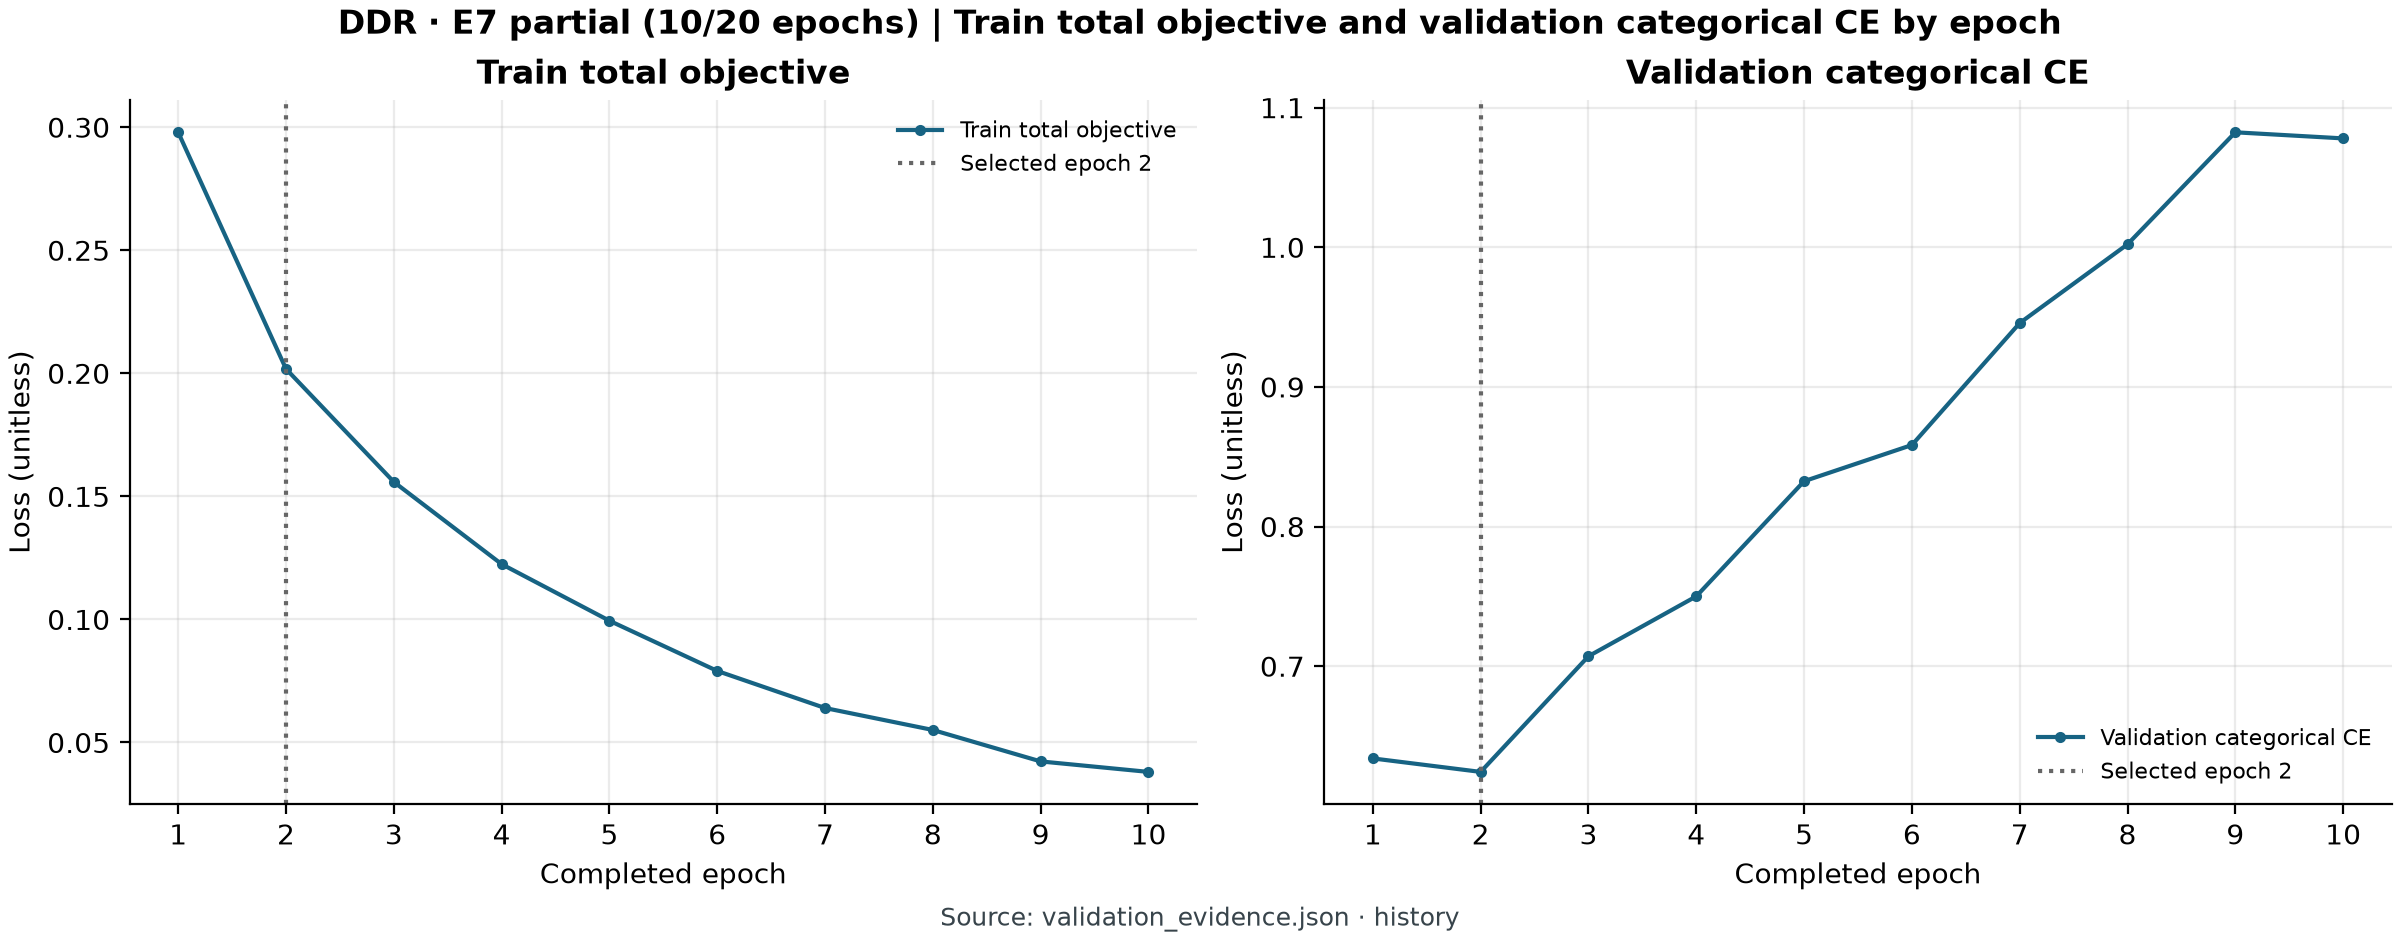

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'docs/figures/ddr_e7_losses.png')))

### Epoch scores

Accuracy, macro-F1 and QWK are plotted for train and validation. All points come from the recorded history. [SVG source view](../../docs/figures/ddr_e7_epoch_scores.svg).

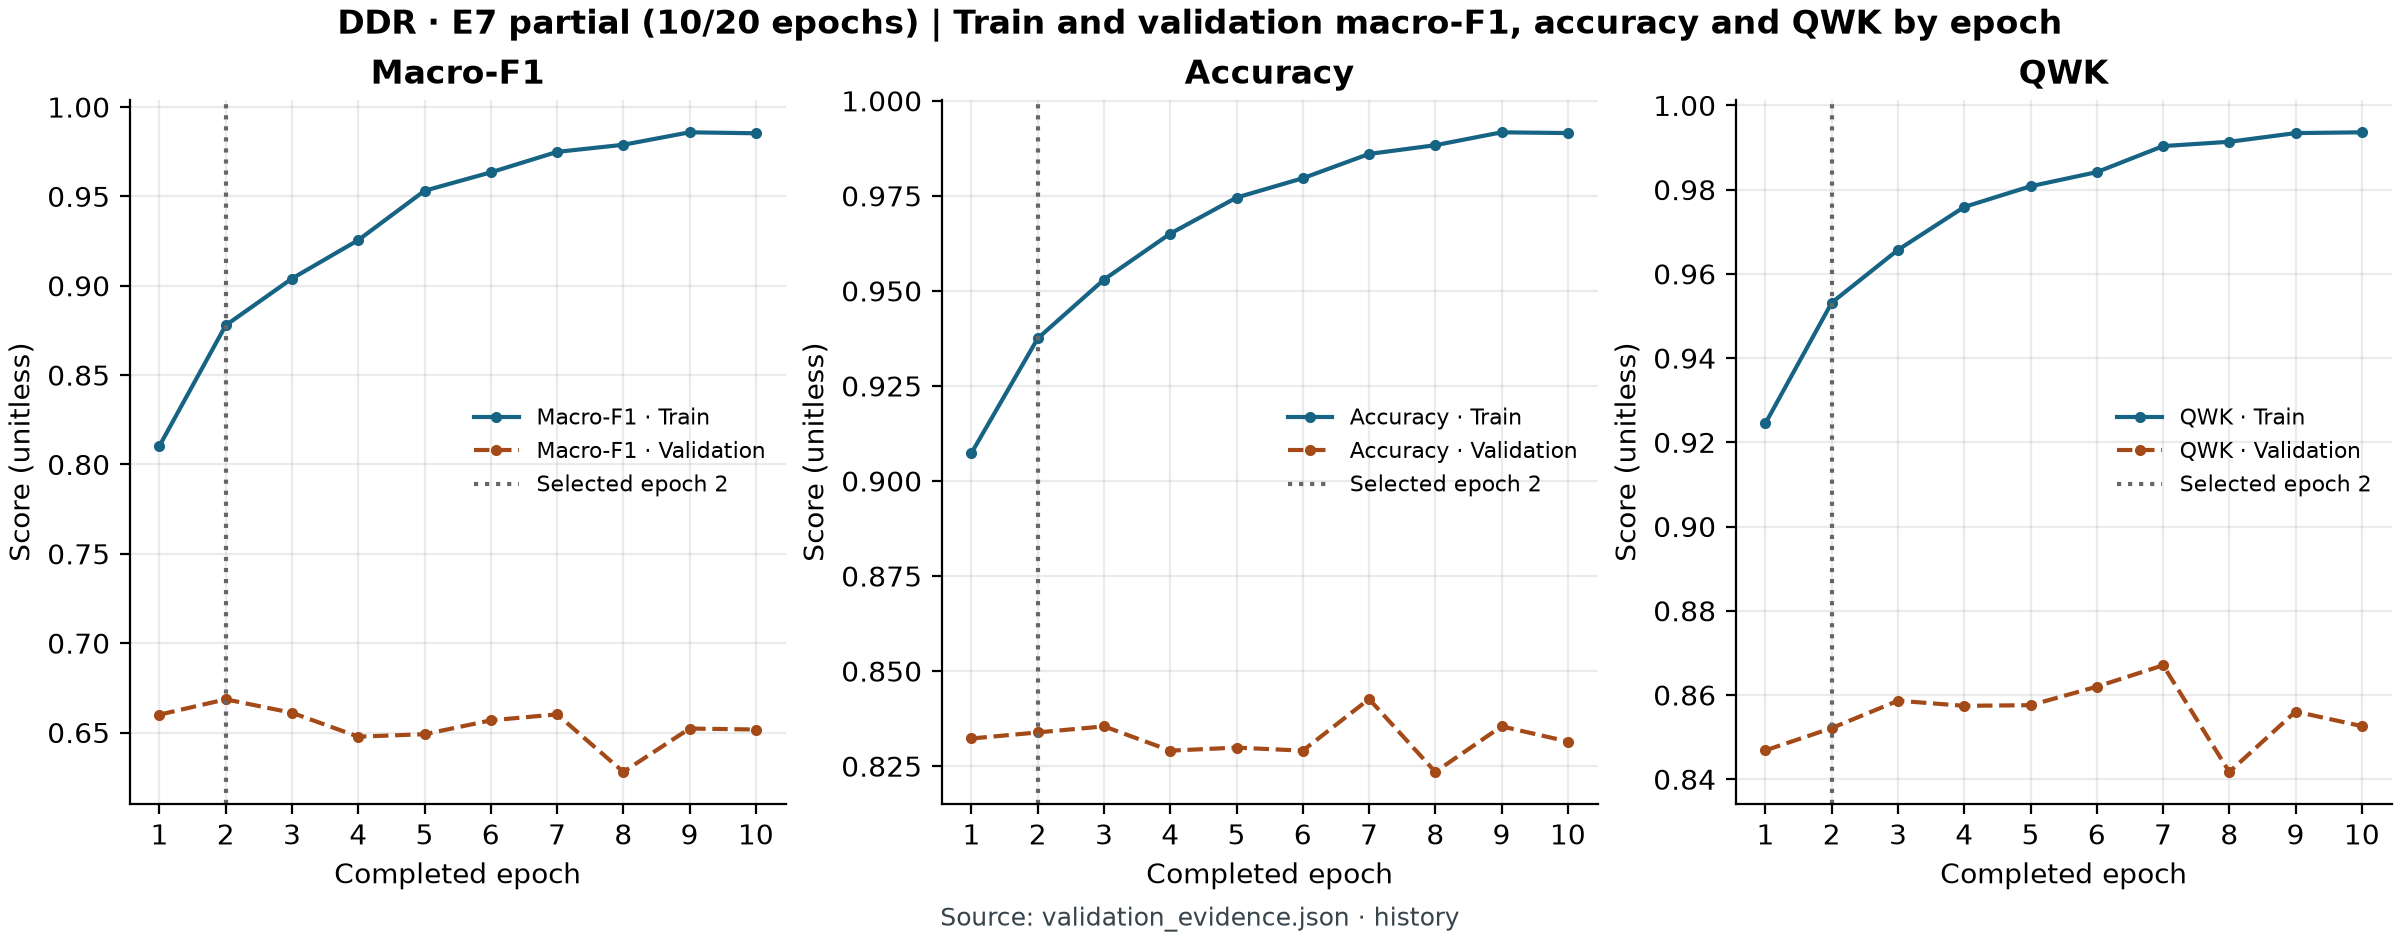

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'docs/figures/ddr_e7_epoch_scores.png')))

### Confusion

The best validation checkpoint is epoch 2. Rows are true grades and columns are predictions. Normalization divides each row by its support. [SVG source view](../../docs/figures/ddr_e7_confusion.svg).

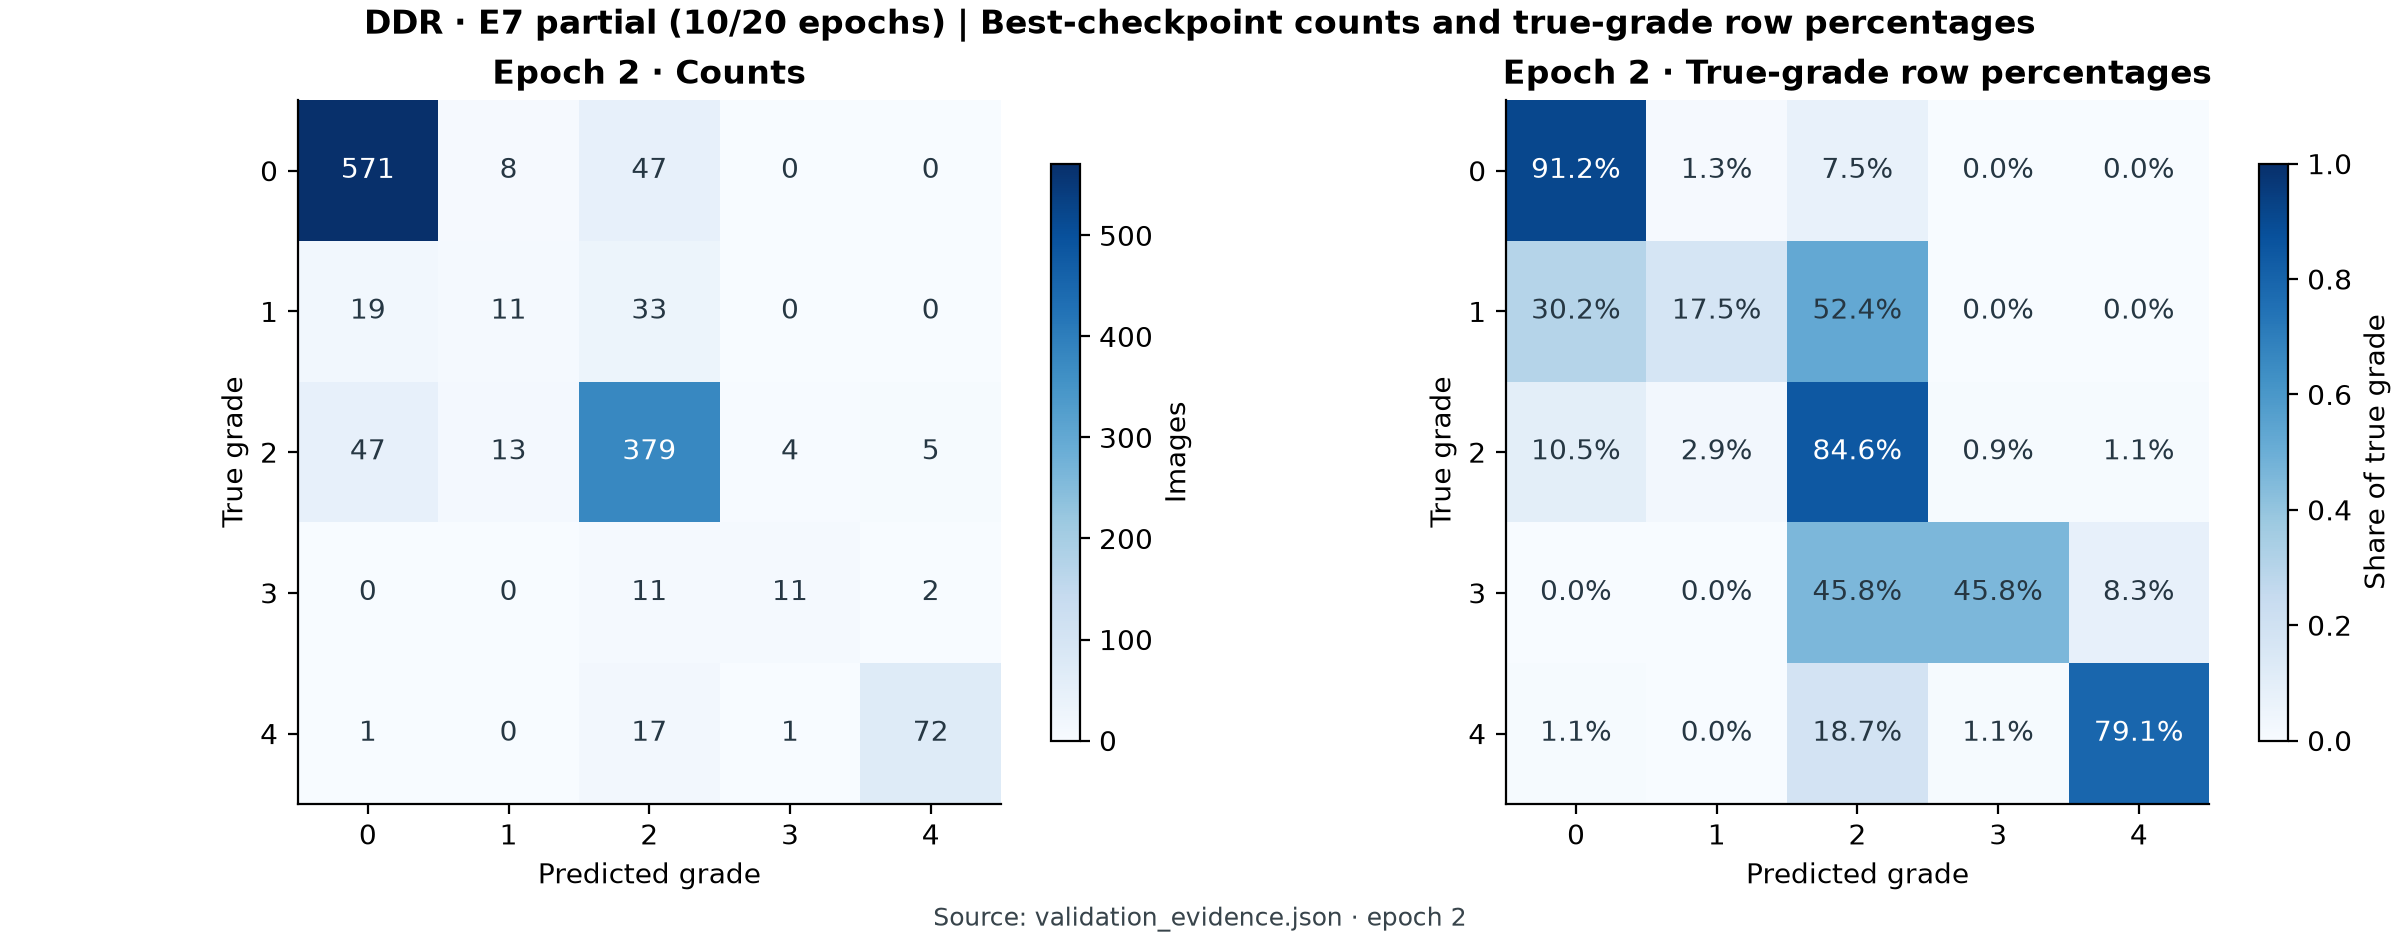

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'docs/figures/ddr_e7_confusion.png')))

### Grade errors

Grade 1 has the smallest F1. Of the 63 validation images with true grade 1, 19 moved down to grade 0 and 33 moved up to grade 2. [SVG source view](../../docs/figures/ddr_e7_grade_errors.svg).

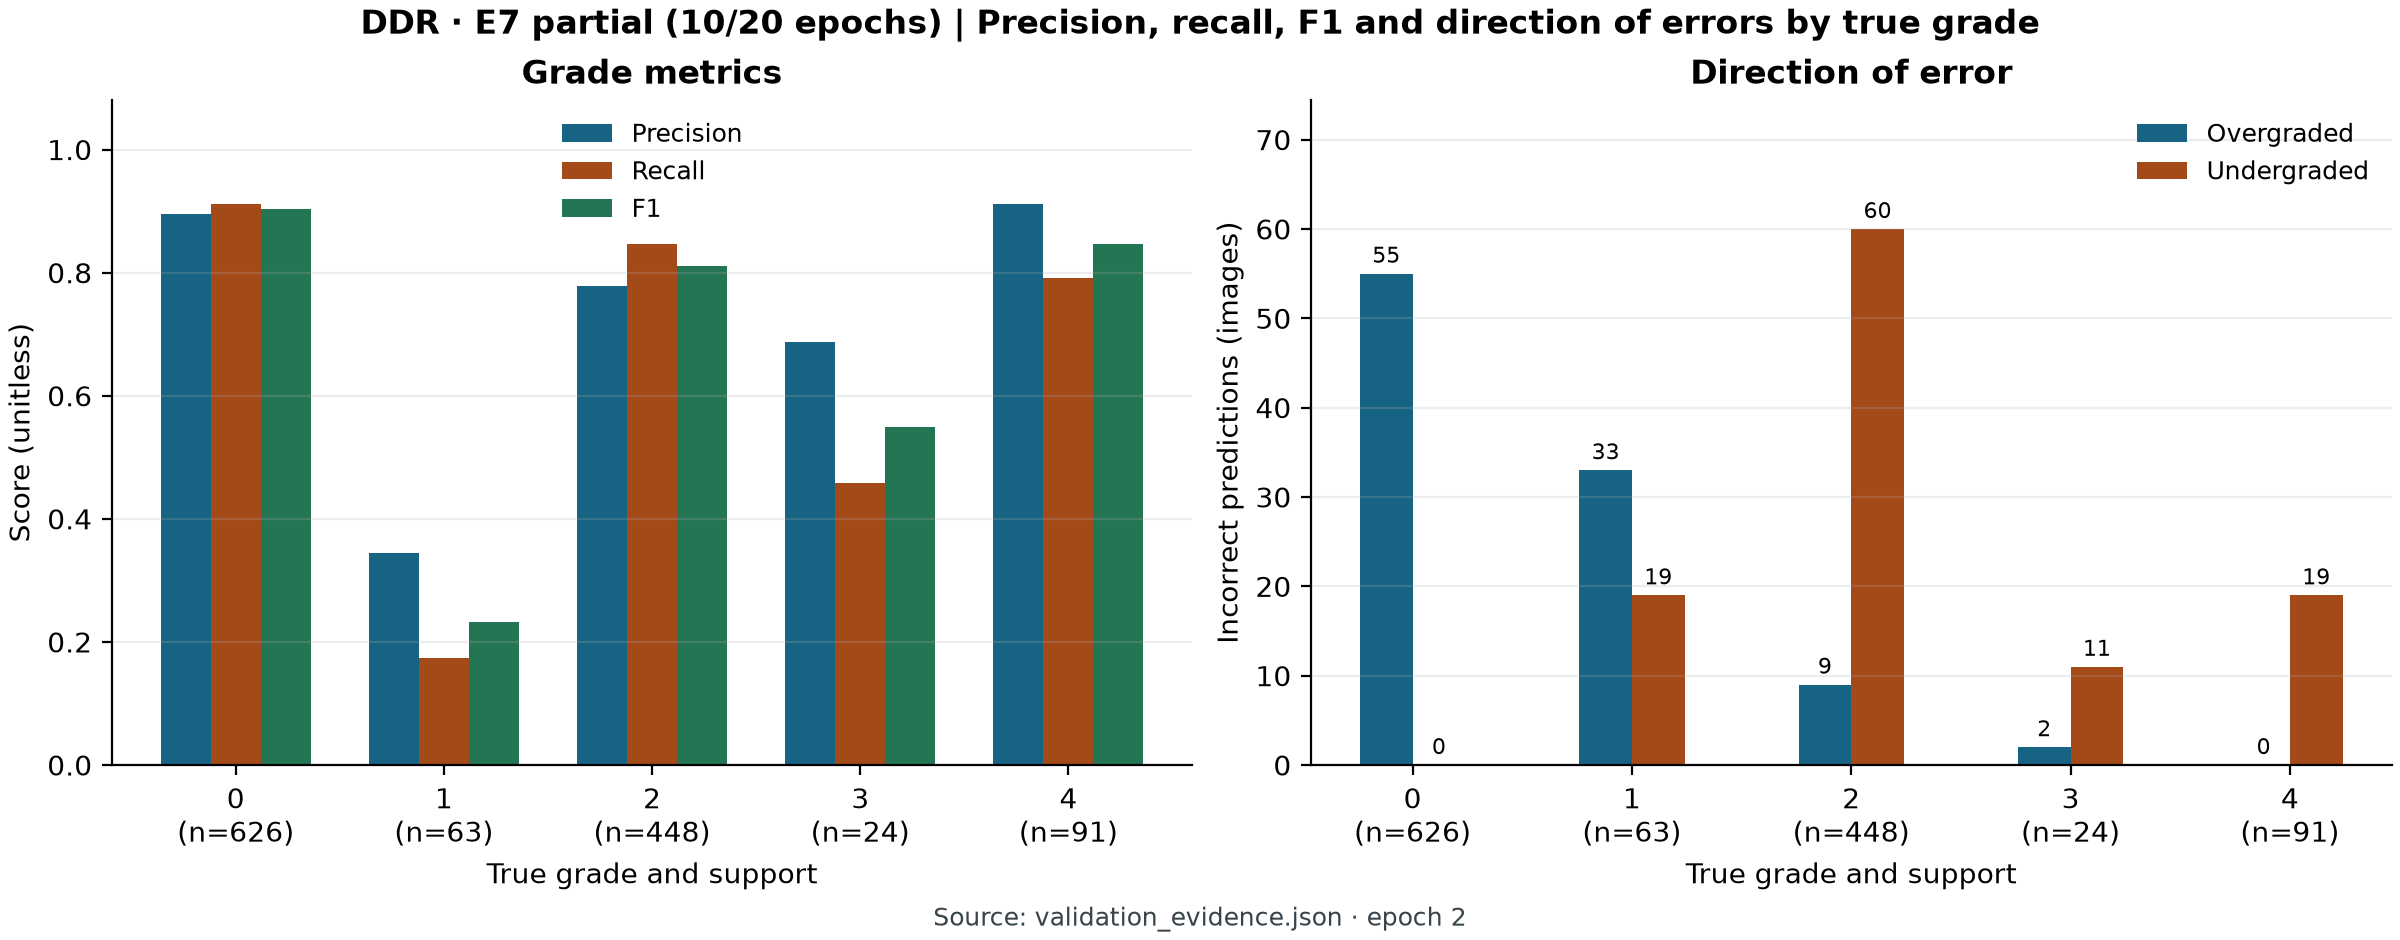

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'docs/figures/ddr_e7_grade_errors.png')))

### E5 e6 e7 comparison

The three selected checkpoints use the same 1,252 frozen validation images. E7 used ten completed epochs. [SVG source view](../../docs/figures/ddr_e7_e5_e6_e7_comparison.svg).

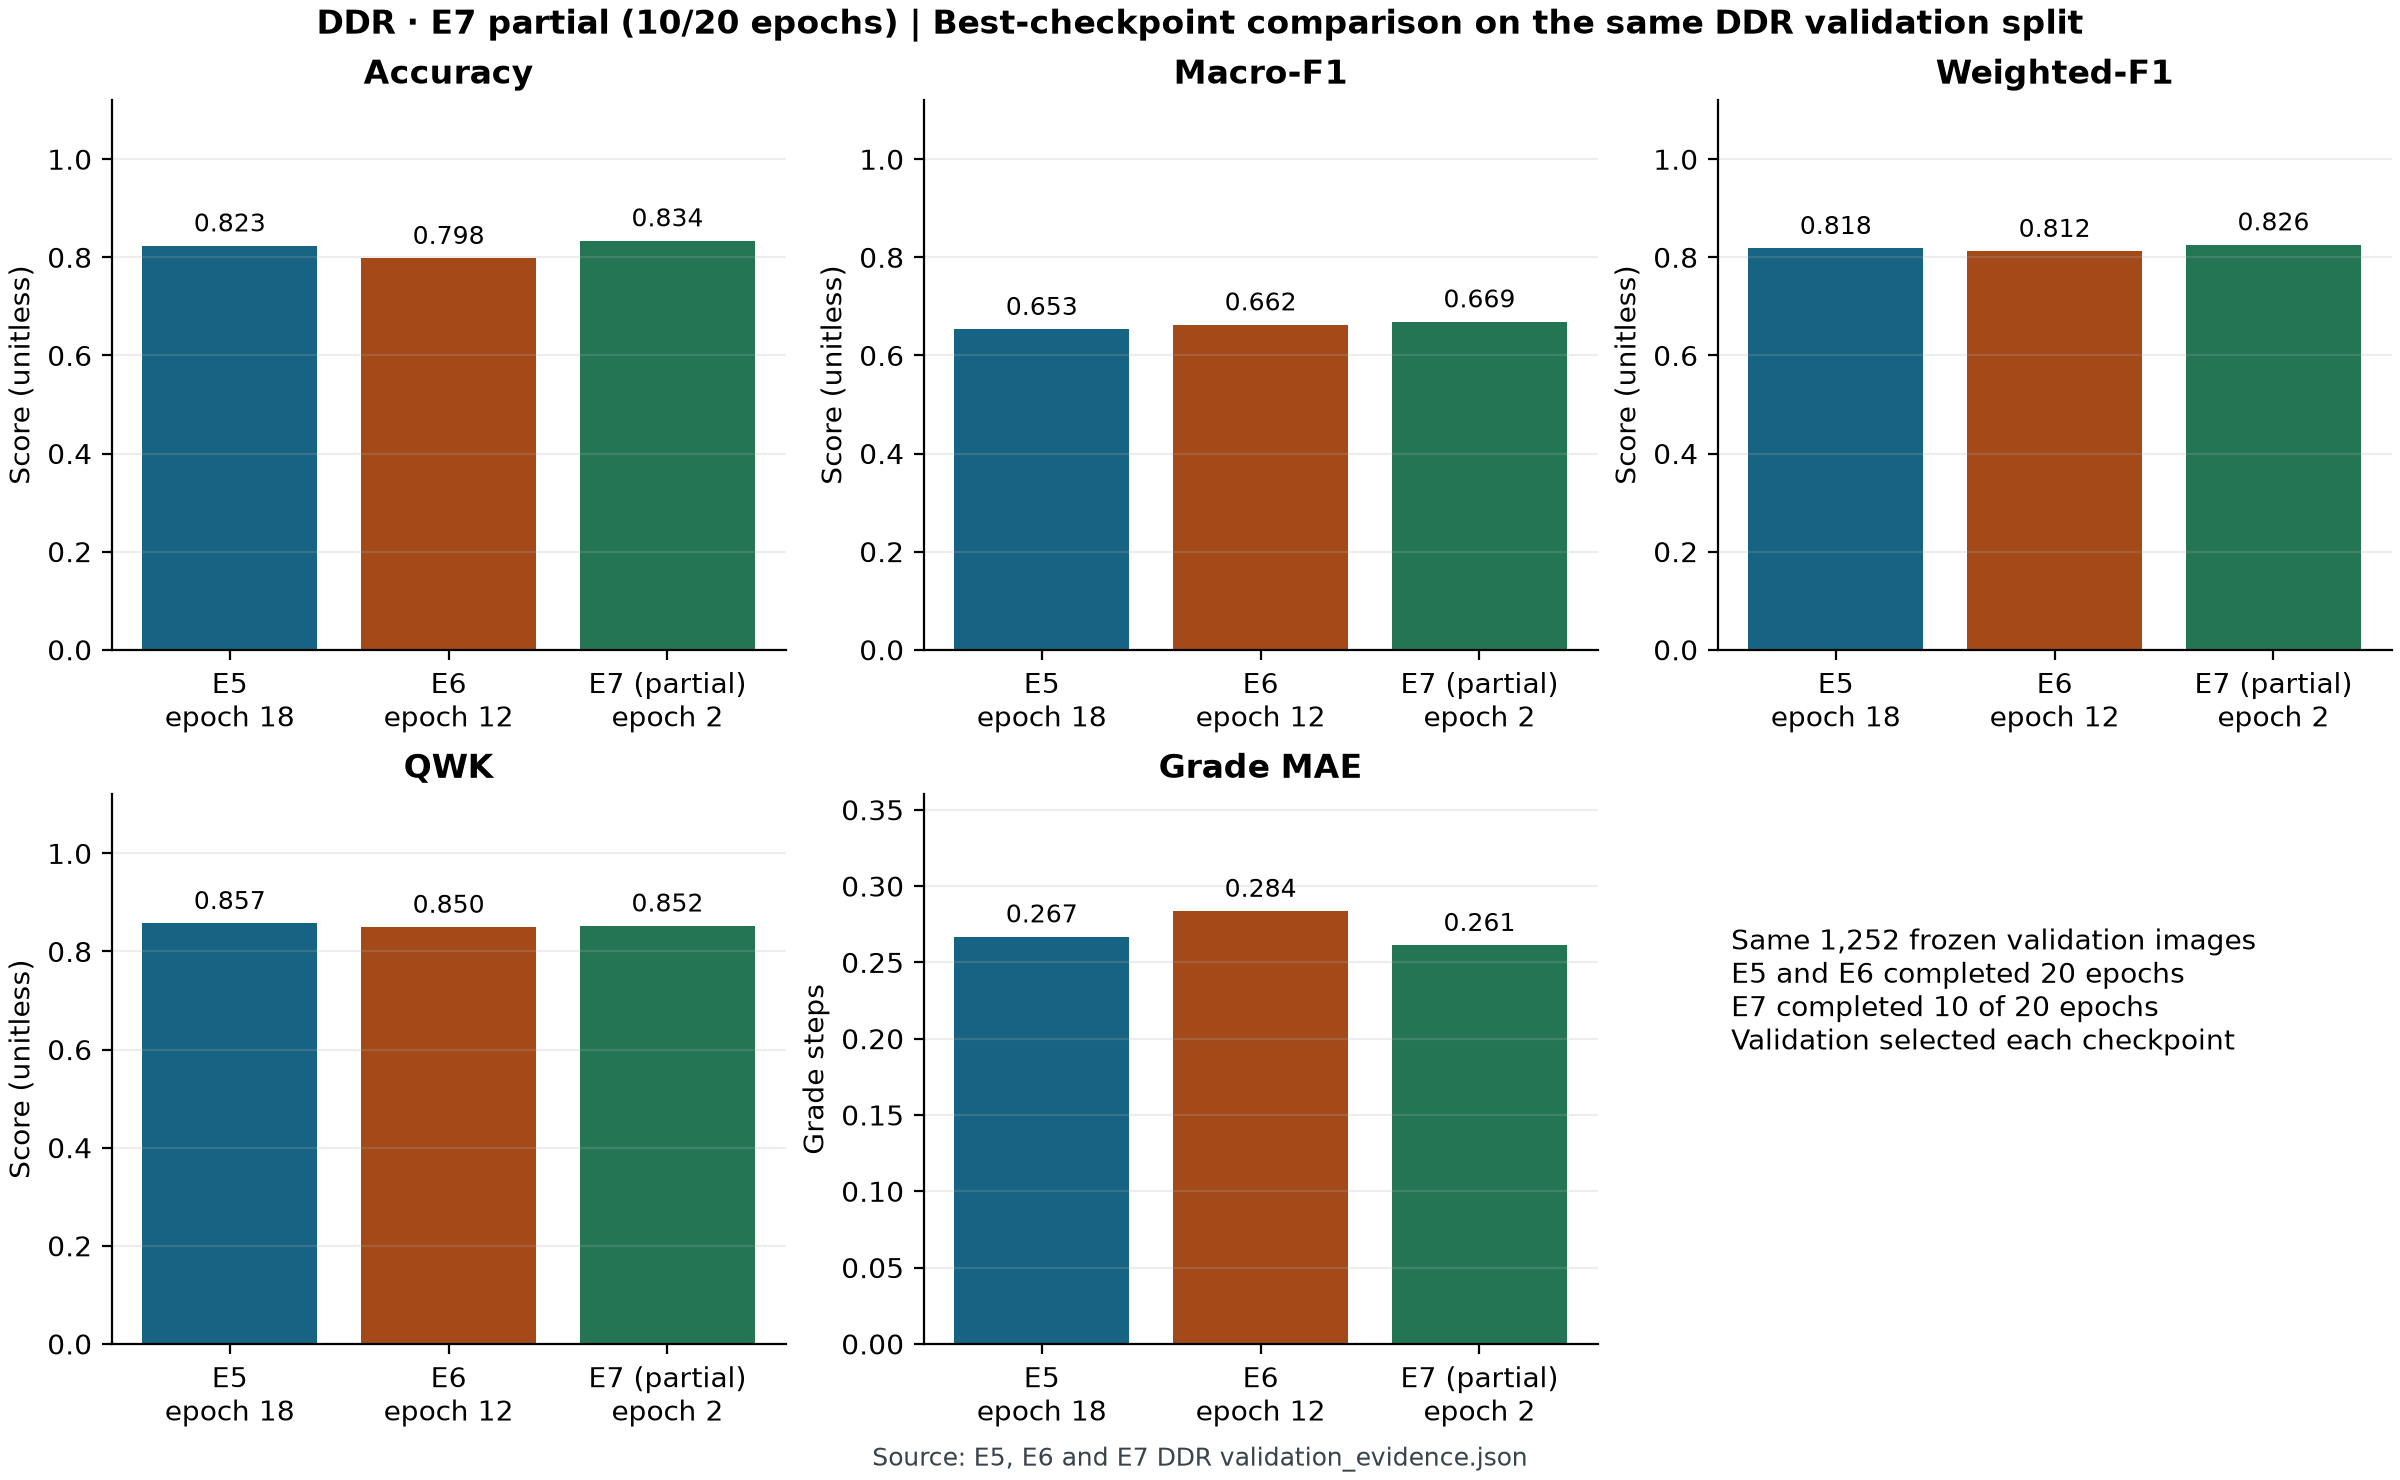

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'docs/figures/ddr_e7_e5_e6_e7_comparison.png')))

### E5, E6 and partial E7 validation comparison

| Frozen DDR validation | E5 | E6 | E7 (partial) |
| --- | --- | --- | --- |
| Epochs completed | 20 | 20 | 10 |
| Selected epoch | 18 | 12 | 2 |
| Accuracy | 0.823482428 | 0.797923323 | 0.833865815 |
| Macro-F1 | 0.653199134 | 0.662455052 | 0.668562794 |
| Weighted-F1 | 0.818187567 | 0.812289836 | 0.825592959 |
| QWK | 0.857161823 | 0.849553202 | 0.852150858 |
| Grade MAE | 0.266773163 | 0.283546326 | 0.261182109 |
| Grade 1 recall | 0.190476 | 0.365079 | 0.174603 |
| Grade 3 recall | 0.541667 | 0.458333 | 0.458333 |

## Interpretation and limits

E7 leads the three selected DDR checkpoints in macro-F1 and accuracy. E5 retains higher QWK. E7 grade 1 recall is 11/63, below E5 and E6. Grade 3 recall is 11/24, tied with E6 and below E5. E7 recorded 99 overgraded and 109 undergraded predictions. Train loss fell while validation CE rose after epoch 2. Checkpoints were selected on the same validation split, and training budgets and objectives differ. These are descriptive findings from one run per method. Final test remains NOT_ACCESSED.

[Full validation report and figure index](../../results/DDR/e7_global_local/validation_report.md).

## Reproduce the report

The notebook only reads committed aggregate results and optionally checks hashes. The figure generator reads the same ten epoch objects. From the repository root, run `python -m docs.e7_ddr_publication --figures ../e7-ddr-rendered` into a fresh directory. See the [figure and source audit](../../docs/FIGURE_PROVENANCE_AUDIT.md).